# Fine-tuning curves

Every segmenter trained by `mxseg train` under `runs/<row>_s<seed>/`, read through `mxseg.train.history` (Lightning's
`logs/metrics.csv`, `resolved_config.yaml`, `data_manifest.json`, `summary.json`). All rows of the paper share one
protocol: the same patches of the development slide and the same augmentation draws per seed, the same input, the same
optimizer and 10-epoch budget, and the same rule for the weights of record — the epoch with the **minimum validation
loss** on the two validation regions (14 and 15), starred in every figure. Every encoder is a ViT-B/16 (KODIAK pretrained on the development slide, `runs/kodiak_mxif_vitb`; DINOv3 as released). Three seeds per row: a seed changes the
initialization of the new layers, the batch order, stochastic depth and the augmentation draws, nothing else. Two levels of
detail: the overview figures draw one line per method — the mean over its seeds, a ± 1 std band where it matters, and the
kept epochs as ticks along the bottom — and one small-multiples grid shows every method on its own row with its seeds and
their kept epochs. Per-step and per-epoch curves are kept apart and shown raw. Works while runs are still training; rows are labelled and colored from their own
resolved config, so a new run needs no edit here.

| figure | content |
|---|---|
| 1 | training loss per optimizer step, one panel per loss part |
| 2 | train and validation loss per epoch, means over seeds, kept epochs as ticks |
| 3 | the headline validation metrics per epoch (F1, AP, PQ) — real inference on the validation metric patches, scored like `mxseg eval` |
| 4 | small multiples: one row per method, its seeds and kept epochs, the other methods' means in gray |
| 5 | the learning-rate schedules actually applied (peak group and deepest trained group) |
| 6 | validation F1 of the kept weights over seeds, and the epoch at which each seed first came within 2 % of its peak F1 |

In [1]:
import fnmatch, json, re
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, ScalarFormatter

from mxseg.train.history import list_runs, runs_table

# ---- edit here ---------------------------------------------------------------------------------------------------------
ROWS = None                          # None = every paper row found under runs/ (paper order first), or a list of row names in legend order
INCLUDE, EXCLUDE = ["*"], ["_*"]     # glob patterns on run names, applied when ROWS is None (the default drops _smoke_* runs)
HEADLINE = ["val/f1", "val/ap", "val/pq"]                                  # figure 3: the overview metrics, one panel each
DETAIL = ["val/loss", "val/f1", "val/precision", "val/recall", "val/count_ratio"]   # figure 4: the small-multiples columns
SHOW_SEEDS = False                   # overview figures 1-3: also draw every seed as a thin line (the grid of figure 4 always does)
STEP_SMOOTH = 0                      # figure 1: 0 = raw; n = centred moving average over n logged steps
SAVE = None                          # e.g. REPO / "LaTex" / "figures" / "curves": every figure also written as PDF + PNG
# ------------------------------------------------------------------------------------------------------------------------

plt.rcParams.update({
    "figure.dpi": 135, "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 8.5, "axes.titlesize": 9, "axes.titleweight": "bold", "axes.labelsize": 8.5,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.7, "xtick.major.width": 0.7, "ytick.major.width": 0.7,
    "xtick.major.size": 2.6, "ytick.major.size": 2.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "legend.frameon": False, "figure.facecolor": "white", "savefig.facecolor": "white",
    "axes.titlelocation": "left",
})
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
INK, MUTED, GRID = "#1A1C1F", "#6B7075", "#E4E6E9"
PAPER = ["unet_flows", "kodiakb_flows", "dinov3b_flows", "kodiakb_frozen", "dinov3b_frozen", "cellpose_ft"]   # the paper's rows, in order
LABEL = {"unet_flows": "U-Net", "kodiakb_flows": "KODIAK B/16", "dinov3b_flows": "DINOv3 B/16", "kodiakb_frozen": "KODIAK B/16, frozen",
         "dinov3b_frozen": "DINOv3 B/16, frozen", "cellpose_ft": "Cellpose, adapted",
         "kodiak_flows": "KODIAK S/16", "dinov3_flows": "DINOv3 S/16", "kodiak_frozen": "KODIAK S/16, frozen", "dinov3_frozen": "DINOv3 S/16, frozen"}   # ViT-S rows: tolerated if ever present
MCOLOR = {"unet_flows": "#2A78D6", "kodiakb_flows": "#7E1F2E", "dinov3b_flows": "#6E5314", "kodiakb_frozen": "#DF959E",
          "dinov3b_frozen": "#D3BF8C", "cellpose_ft": "#EB6834",
          "kodiak_flows": "#C43E4E", "dinov3_flows": "#B08A2E", "kodiak_frozen": "#DF959E", "dinov3_frozen": "#D3BF8C"}   # the paper's swatches
FAMILY = {"kodiak": ("KODIAK", "#7E1F2E"), "dinov3": ("DINOv3", "#6E5314"), "unet": ("U-Net", "#2A78D6"),
          "cellpose": ("Cellpose", "#EB6834"), "scratch": ("ViT scratch", "#8A8A8A")}                        # any other run: by family
SEED_RE = re.compile(r"^(.*)_s(\d+)$")

def panel(ax, letter, dx=-0.04, dy=1.04):
    ax.text(dx, dy, letter, transform=ax.transAxes, fontsize=11.5, fontweight="bold", va="bottom", ha="right", color=INK)

def ygrid(ax):
    ax.grid(axis="y", color=GRID, lw=0.7, zorder=0); ax.set_axisbelow(True)

def xgrid(ax):
    ax.grid(axis="x", color=GRID, lw=0.7, zorder=0); ax.set_axisbelow(True)

def epoch_axis(ax):
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))

def lighten(hexcol, f=0.45):
    c = np.array([int(hexcol[i:i + 2], 16) for i in (1, 3, 5)]) / 255
    return "#" + "".join(f"{int(round(255 * v)):02X}" for v in c + (1 - c) * f)

def finish(fig, name, handles=None, ncol=4):
    if handles:
        fig.legend(handles=handles, ncol=min(ncol, len(handles)), loc="lower center", bbox_to_anchor=(0.5, -0.01),
                   fontsize=7.4, handlelength=1.8, columnspacing=1.2)
    if SAVE:
        Path(SAVE).mkdir(parents=True, exist_ok=True)
        fig.savefig(Path(SAVE) / f"{name}.pdf", bbox_inches="tight")
        fig.savefig(Path(SAVE) / f"{name}.png", bbox_inches="tight", dpi=300)
    plt.show()

class Run:
    """One run directory: its row and seed (from the name), family, frozen or not, objective, input — from its resolved config."""
    def __init__(self, h):
        self.h, self.name = h, h.name
        m = SEED_RE.match(h.name)
        self.row, self.seed = (m.group(1), int(m.group(2))) if m else (h.name, None)
        model = h.config.get("model"); sec = h.config.get(model, {})
        if model == "kodiak":
            ck = sec.get("checkpoint") or ""
            self.family = "dinov3" if ck.endswith(".pth") else "kodiak" if ck else "scratch"
            self.frozen, self.objective = sec.get("train_blocks", 12) == 0, sec.get("objective", "flows")
        elif model == "unet":
            self.family, self.frozen, self.objective = "unet", False, sec.get("objective", "flows")
        else:
            self.family, self.frozen, self.objective = "cellpose", sec.get("train_blocks", 24) == 0, "flows"
        man = h.path / "data_manifest.json"
        inp = json.loads(man.read_text()).get("input", {}) if man.is_file() else {}
        self.input = "·".join(str(c) if c else "—" for c in inp["channels"]) if inp.get("channels") else inp.get("mode", "?")
        self.done = bool(h.summary)

    @property
    def epochs(self): return self.h.epochs
    @property
    def steps(self): return self.h.steps
    @property
    def val(self): return self.h.val_metrics
    def kept(self, table):
        """The row of ``table`` (per-epoch) at the kept epoch, or None."""
        if self.h.best_epoch is None:
            return None
        k = table[table["epoch"] == self.h.best_epoch]
        return k.iloc[0] if len(k) else None
    def lr_groups(self):
        """Learning rate per epoch for every optimizer group (Lightning's LearningRateMonitor columns)."""
        raw = pd.read_csv(self.h.path / "logs" / "metrics.csv")
        cols = [c for c in raw.columns if c.startswith("lr-")]
        g = raw.dropna(subset=cols, how="all")[["step", *cols]]
        spe = max(int(self.steps["step"].max() // max(len(self.epochs), 1)), 1) if len(self.steps) and len(self.epochs) else 1
        g["epoch"] = (g["step"] // spe).astype(int)
        return g.groupby("epoch")[cols].max()

class Row:
    """A paper row = the runs of one method over seeds: label, color, and mean / std curves across its seeds."""
    def __init__(self, name, runs):
        self.name, self.runs = name, sorted(runs, key=lambda r: (r.seed is None, r.seed or 0))
        r0 = self.runs[0]
        self.family, self.frozen, self.objective, self.input = r0.family, r0.frozen, r0.objective, r0.input
        fam_label, fam_color = FAMILY[self.family]
        self.label = LABEL.get(name) or fam_label + (", frozen" if self.frozen else "") + (" (3-class)" if self.objective == "threeclass" else "")
        self.color = MCOLOR.get(name) or (lighten(fam_color) if self.frozen else fam_color)
        self.ls = (0, (4, 2)) if self.frozen else "-"
    @property
    def seeds(self): return [r.seed for r in self.runs]
    def handle(self):
        return plt.Line2D([], [], color=self.color, ls=self.ls, lw=1.6, label=f"{self.label} (n = {len(self.runs)})")
    def curve(self, table_of, x, col):
        """(per-seed tables with x, col) and the mean / std over seeds at every x present in at least one seed."""
        parts = []
        for r in self.runs:
            t = table_of(r)
            if col in t and t[col].notna().any():
                parts.append(t.dropna(subset=[col])[[x, col]].assign(seed=r.seed))
        if not parts:
            return [], None
        allp = pd.concat(parts)
        agg = allp.groupby(x)[col].agg(["mean", "std", "count"]).reset_index()
        return parts, agg
    def kept_points(self, table_of, col):
        """(x, y) of the kept epoch of every seed, for a per-epoch table."""
        pts = []
        for r in self.runs:
            k = r.kept(table_of(r))
            if k is not None and col in k and pd.notna(k[col]):
                pts.append((k["epoch"] + 1, k[col]))
        return pts

def draw(ax, row, table_of, x, col, band=True, seeds=None, stars=False, x_offset=0, lw=1.4, alpha=1.0, marker=True):
    """A row's curve: the mean over seeds (a ± std band, optionally the seeds as thin lines and a star per seed at its kept epoch)."""
    seeds = SHOW_SEEDS if seeds is None else seeds
    parts, agg = row.curve(table_of, x, col)
    if agg is None:
        return
    if seeds and len(parts) > 1:
        for p in parts:
            ax.plot(p[x] + x_offset, p[col], lw=0.6, color=row.color, ls=row.ls, alpha=0.45)
    if band and len(parts) > 1:
        ax.fill_between(agg[x] + x_offset, agg["mean"] - agg["std"].fillna(0), agg["mean"] + agg["std"].fillna(0), color=row.color, alpha=0.12, lw=0)
    ax.plot(agg[x] + x_offset, agg["mean"], lw=lw, color=row.color, ls=row.ls, alpha=alpha, marker="o" if (marker and x == "epoch") else None, ms=2.2)
    if stars and x == "epoch":
        for px, py in row.kept_points(table_of, col):
            ax.plot(px, py, marker="*", ms=7.5, color=row.color, mec=INK, mew=0.5, ls="", zorder=5)

def rug(ax, rows, table_of, col):
    """The kept epoch of every seed as a short tick along the bottom of the axis, one lane per method, in the method's color."""
    import matplotlib.transforms as mtr
    tr = mtr.blended_transform_factory(ax.transData, ax.transAxes)
    for i, row in enumerate(rows):
        xs = [px for px, _ in row.kept_points(table_of, col)]
        if xs:
            ax.plot(xs, [0.012 + 0.03 * i] * len(xs), marker="|", ms=5, mew=1.3, ls="", color=row.color, transform=tr, clip_on=False, zorder=6)

TICK = plt.Line2D([], [], marker="|", ms=7, mew=1.3, color=INK, ls="", label="kept epoch of a seed (min val/loss), one lane per method")

hists = [h for h in list_runs(REPO / "runs") if isinstance(h.config.get("model"), str)]   # fine-tuning runs, not the pretraining
hists = [h for h in hists if any(fnmatch.fnmatch(h.name, p) for p in INCLUDE) and not any(fnmatch.fnmatch(h.name, p) for p in EXCLUDE)]
if not hists:
    raise FileNotFoundError("no fine-tuning runs with logs under runs/ — scripts/finetune_all.sh trains the paper's rows")
runs = [Run(h) for h in hists]
by_row = {}
for r in runs:
    by_row.setdefault(r.row, []).append(r)
order = ROWS or sorted(by_row, key=lambda n: (PAPER.index(n) if n in PAPER else len(PAPER), n))
rows = [Row(n, by_row[n]) for n in order if n in by_row]
HANDLES = [r.handle() for r in rows]
STAR = plt.Line2D([], [], marker="*", ms=9, color="white", mec=INK, mew=0.6, ls="", label="kept epoch of a seed (min val/loss)")
GRAY = plt.Line2D([], [], color="#B9BDC2", lw=0.8, label="the other methods (means)")

table = runs_table([r.h for r in runs])
table.insert(0, "row", [LABEL.get(r.row, r.row) for r in runs])
table.insert(1, "seed", [r.seed for r in runs])
table.insert(2, "input", [r.input for r in runs])
table.insert(3, "objective", [r.objective for r in runs])
table = table.sort_values(["row", "seed"], key=lambda s: s.map({LABEL.get(n, n): i for i, n in enumerate(order)}) if s.name == "row" else s)
cols = ["row", "seed", "input", "objective", "lr", "batch", "epochs", "epochs_done", "finished", "best_epoch", "best_val_loss", "best_val_f1", "max_val_f1", "final_val_f1"]
display(table[[c for c in cols if c in table.columns]].style.format({"lr": "{:.1e}", "best_val_loss": "{:.3f}", "best_val_f1": "{:.3f}", "max_val_f1": "{:.3f}", "final_val_f1": "{:.3f}"}, na_rep="—"))
agg_rows = []
for row in rows:
    t = table[table.row == LABEL.get(row.name, row.name)]
    fin = t[t.finished.astype(bool)] if "finished" in t else t
    ms = lambda c: f"{fin[c].mean():.3f} ± {fin[c].std(ddof=0):.3f}" if len(fin) > 1 else (f"{fin[c].iloc[0]:.3f}" if len(fin) else "—")
    agg_rows.append({"row": row.label, "seeds finished": f"{len(fin)} / {len(t)}", "best_epoch": ", ".join(str(int(e) + 1) for e in fin.best_epoch.dropna()) or "—",
                     "best_val_loss": ms("best_val_loss"), "best_val_f1": ms("best_val_f1"), "max_val_f1": ms("max_val_f1")})
print("\nper row, mean ± std over the finished seeds:")
print(pd.DataFrame(agg_rows).to_string(index=False))
inputs = sorted({r.input for r in runs})
print(f"\n{len(runs)} run(s) in {len(rows)} row(s), {sum(r.done for r in runs)} finished | input: " + ", ".join(inputs) +
      (" — WARNING: inputs differ between runs" if len(inputs) > 1 else "") + " | weights of record: epoch of minimum val/loss (best_epoch)")

,row,seed,input,objective,lr,batch,epochs,epochs_done,finished,best_epoch,best_val_loss,best_val_f1,max_val_f1,final_val_f1
run,,,,,,,,,,,,,,
unet_flows_s0,U-Net,0,LAP2·—·DAPI,flows,2.0e-03,16,10,10,True,9,0.891,0.865,0.865,0.865
unet_flows_s1,U-Net,1,LAP2·—·DAPI,flows,2.0e-03,16,10,10,True,9,0.877,0.864,0.864,0.864
unet_flows_s2,U-Net,2,LAP2·—·DAPI,flows,2.0e-03,16,10,10,True,7,0.871,0.864,0.864,0.856
kodiakb_flows_s0,KODIAK B/16,0,LAP2·—·DAPI,flows,2.0e-03,4,10,10,True,6,0.847,0.874,0.890,0.888
kodiakb_flows_s1,KODIAK B/16,1,LAP2·—·DAPI,flows,2.0e-03,4,10,10,True,9,0.862,0.877,0.879,0.877
kodiakb_flows_s2,KODIAK B/16,2,LAP2·—·DAPI,flows,2.0e-03,4,10,10,True,8,0.854,0.884,0.887,0.887
dinov3b_flows_s0,DINOv3 B/16,0,LAP2·—·DAPI,flows,2.0e-03,4,10,10,True,9,0.955,0.865,0.865,0.865
dinov3b_flows_s1,DINOv3 B/16,1,LAP2·—·DAPI,flows,2.0e-03,4,10,10,True,9,0.982,0.847,0.853,0.847
dinov3b_flows_s2,DINOv3 B/16,2,LAP2·—·DAPI,flows,2.0e-03,4,10,10,True,8,0.914,0.866,0.866,0.864



per row, mean ± std over the finished seeds:
                row seeds finished best_epoch best_val_loss   best_val_f1    max_val_f1
              U-Net          3 / 3  10, 10, 8 0.880 ± 0.008 0.864 ± 0.000 0.864 ± 0.001
        KODIAK B/16          3 / 3   7, 10, 9 0.854 ± 0.006 0.878 ± 0.004 0.886 ± 0.005
        DINOv3 B/16          3 / 3  10, 10, 9 0.950 ± 0.028 0.859 ± 0.009 0.861 ± 0.006
KODIAK B/16, frozen          3 / 3    7, 8, 9 1.041 ± 0.010 0.800 ± 0.007 0.805 ± 0.007
DINOv3 B/16, frozen          3 / 3   10, 8, 9 0.994 ± 0.013 0.836 ± 0.006 0.840 ± 0.004
  Cellpose, adapted          3 / 3    7, 5, 9 0.791 ± 0.004 0.890 ± 0.002 0.897 ± 0.001

18 run(s) in 6 row(s), 18 finished | input: LAP2·—·DAPI | weights of record: epoch of minimum val/loss (best_epoch)


## 1. Training loss per step

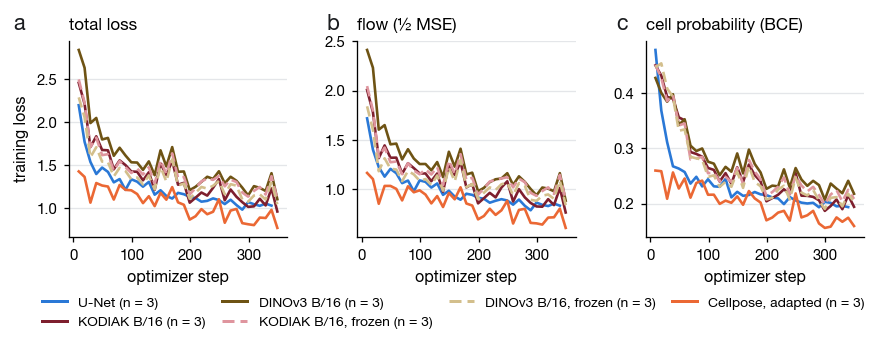

In [2]:
PARTS = {"train/loss": "total loss", "train/flow": "flow (½ MSE)", "train/prob": "cell probability (BCE)",
         "train/ce": "cross-entropy", "train/dice": "Dice"}
present = [p for p in PARTS if any(p in r.steps and r.steps[p].notna().any() for r in runs)]
fig, axes = plt.subplots(1, len(present), figsize=(7.6, 2.5))
axes = np.atleast_1d(axes)
def steps_of(r):
    s = r.steps
    if STEP_SMOOTH > 1:
        s = s.copy()
        for p in present:
            if p in s:
                s[p] = s[p].rolling(STEP_SMOOTH, center=True, min_periods=1).mean()
    return s
for ax, part in zip(axes, present):
    for row in rows:
        draw(ax, row, steps_of, "step", part, band=False, stars=False)
    ax.set_title(PARTS[part]); ax.set_xlabel("optimizer step"); ygrid(ax)
axes[0].set_ylabel("training loss" + (f" (moving average, {STEP_SMOOTH})" if STEP_SMOOTH > 1 else ""))
for a, letter in zip(axes, "abcde"):
    panel(a, letter, dx=-0.2 if a is axes[0] else -0.08)
fig.subplots_adjust(bottom=0.3, wspace=0.32)
finish(fig, "ft_step_loss", HANDLES)

**Figure 1 — Training loss per optimizer step**, raw values as logged (every tenth step), one panel per part of the
loss: under the flow objective Cellpose's ½·MSE on the flow field plus binary cross-entropy on the cell probability,
averaged over pixels outside the ignore mask. One line per method: the mean over its seeds at every logged step
(`SHOW_SEEDS = True` adds the seeds). Frozen encoders are dashed. Steps, not epochs: runs with gradient accumulation take the same number of
optimizer steps per epoch as the rest (one step = 16 patches for every row).

## 2. Loss per epoch

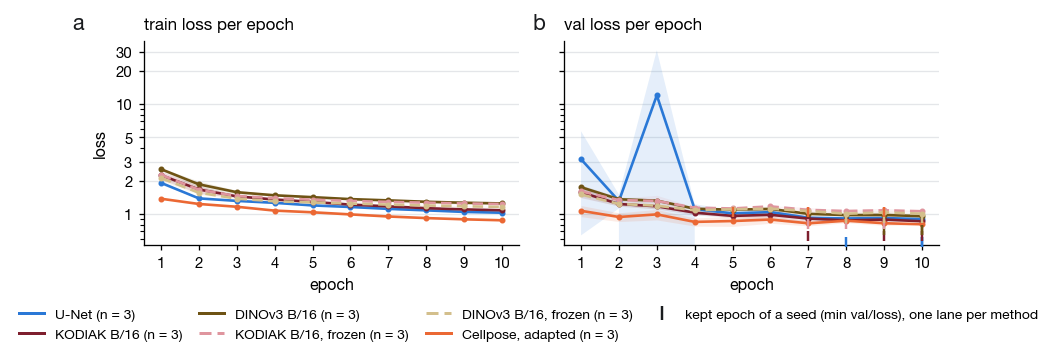

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(7.6, 2.6), sharey=True)
for ax, split in zip(axes, ("train", "val")):
    for row in rows:
        draw(ax, row, lambda r: r.epochs, "epoch", f"{split}/loss", x_offset=1)
    ax.set_title(f"{split} loss per epoch"); ax.set_xlabel("epoch"); ygrid(ax); epoch_axis(ax)
rug(axes[1], rows, lambda r: r.epochs, "val/loss")
vals = np.concatenate([r.epochs[c].dropna().values for r in runs for c in ("train/loss", "val/loss") if c in r.epochs] or [np.array([])])
if len(vals) and vals.max() / max(vals[vals > 0].min(), 1e-9) > 8:        # a first epoch far above the rest: log axis
    from matplotlib.ticker import LogLocator, NullFormatter
    for ax in axes:
        ax.set_yscale("log")
        ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 3.0, 5.0)))
        ax.yaxis.set_major_formatter(ScalarFormatter()); ax.yaxis.set_minor_formatter(NullFormatter())
axes[0].set_ylabel("loss")
panel(axes[0], "a", dx=-0.16); panel(axes[1], "b", dx=-0.05)
fig.subplots_adjust(bottom=0.3, wspace=0.12)
finish(fig, "ft_epoch_loss", HANDLES + [TICK], ncol=4)

**Figure 2 — Train (a) and validation (b) loss per epoch.** Epoch means as logged: train over the epoch's steps,
validation over the validation patches of regions 14 and 15 under the same loss and ignore mask. One line per method, the mean over
its seeds with a ± 1 std band; the ticks along the bottom of (b) are the epochs whose weights each seed keeps — the minimum
of its own validation-loss curve — one lane per method. The gap between the panels is the overfitting margin, smallest for a frozen encoder; the width of the band is how
much the seed alone moves a method. The axis turns logarithmic when a first epoch sits far above the rest.

## 3. Validation instance metrics per epoch

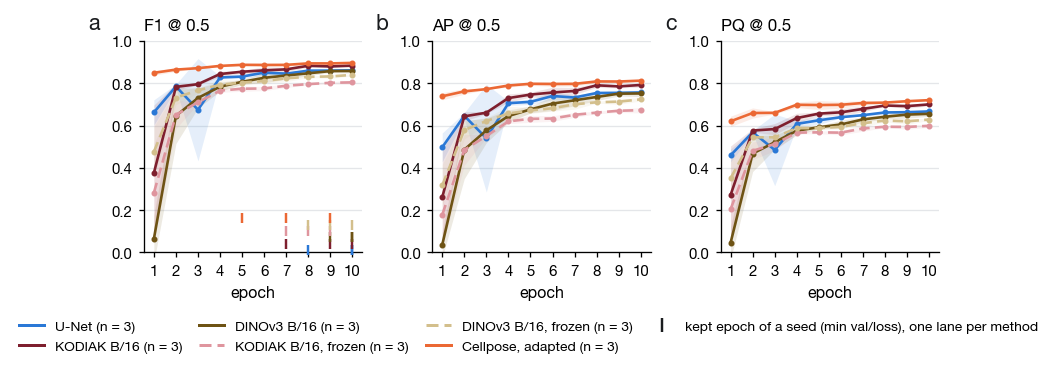

In [4]:
TITLE = {"val/f1": "F1 @ 0.5", "val/ap": "AP @ 0.5", "val/pq": "PQ @ 0.5", "val/ap_50_90": "AP @ 0.5:0.9",
         "val/precision": "precision @ 0.5", "val/recall": "recall @ 0.5", "val/count_ratio": "count ratio"}
fig, axes = plt.subplots(1, len(HEADLINE), figsize=(7.6, 2.7), sharex=True, squeeze=False)
for ax, key in zip(axes.ravel(), HEADLINE):
    for row in rows:
        draw(ax, row, lambda r: r.val, "epoch", key, x_offset=1)
    if key == "val/count_ratio":
        ax.axhline(1.0, color=INK, lw=0.7, alpha=0.5)
    ax.set_title(TITLE.get(key, key)); ax.set_xlabel("epoch"); ygrid(ax); epoch_axis(ax)
    lo = min(float(np.nanmin(r.val[key])) for r in runs if key in r.val and len(r.val)) if any(key in r.val and len(r.val) for r in runs) else 0
    ax.set_ylim(max(0, np.floor((min(lo, 0.5)) * 10) / 10), 1.0 if key != "val/count_ratio" else None)   # the useful range; a collapsed epoch still shows
rug(axes.ravel()[0], rows, lambda r: r.val, HEADLINE[0])
for ax, letter in zip(axes.ravel(), "abcdefgh"):
    panel(ax, letter, dx=-0.2)
fig.subplots_adjust(bottom=0.3, wspace=0.32)
finish(fig, "ft_val_metrics", HANDLES + [TICK], ncol=4)
if not any(len(r.val) for r in runs):
    print("no instance metrics yet — they appear every `val.every_n_epochs` epochs")

**Figure 3 — Validation instance metrics per epoch.** Real inference (flow following, exactly as `mxseg eval`) on the
validation metric patches every epoch, scored on owned, verified nuclei with flagged nuclei ignored. One line per method, the mean over
seeds with a ± 1 std band, for the three metrics the paper reports; the ticks along the bottom of (a) are the seeds' kept
epochs — chosen by the validation loss, not by any of these curves, so a tick before a curve's peak is the price of a
selection rule that is blind to the metric it is later judged by (the same price for every row). Figure 4 shows every
method and seed on its own.

## 4. Every method on its own: seeds, kept epochs, and the field in gray

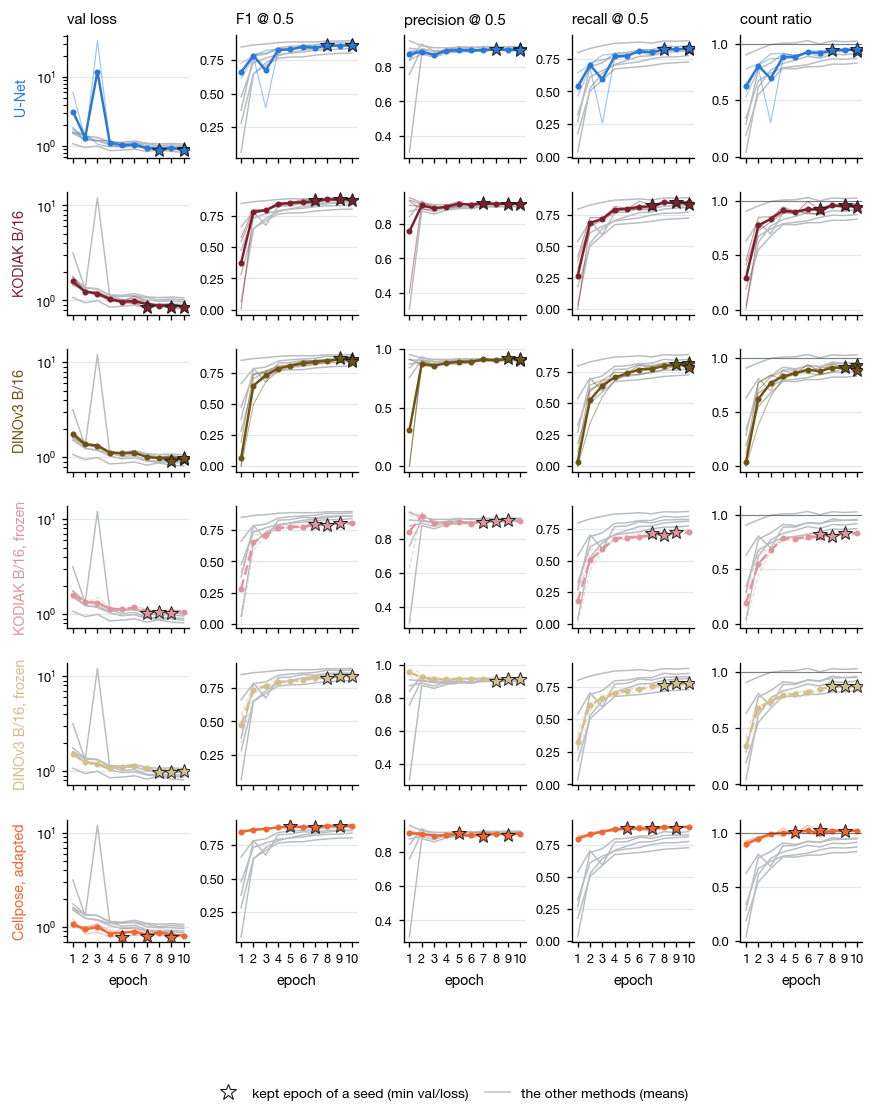

In [5]:
DT = {"val/loss": "val loss", **TITLE}
nr, nc = len(rows), len(DETAIL)
fig, axes = plt.subplots(nr, nc, figsize=(7.6, 1.25 * nr + 0.9), sharex=True, squeeze=False)
for i, row in enumerate(rows):
    for j, key in enumerate(DETAIL):
        ax = axes[i, j]
        table_of = (lambda r: r.epochs) if key == "val/loss" else (lambda r: r.val)
        for other in rows:                                                       # the field: every other method's mean, in gray
            if other is not row:
                draw(ax, other, table_of, "epoch", key, band=False, seeds=False, x_offset=1, lw=0.8, alpha=1.0, marker=False)
                for line in ax.lines[-1:]:
                    line.set_color("#B9BDC2"); line.set_linestyle("-")
        draw(ax, row, table_of, "epoch", key, band=False, seeds=True, stars=True, x_offset=1, lw=1.3)
        if key == "val/count_ratio":
            ax.axhline(1.0, color=INK, lw=0.6, alpha=0.5)
        if key == "val/loss":
            vals = np.concatenate([r.epochs["val/loss"].dropna().values for r in runs if "val/loss" in r.epochs] or [np.array([1.0])])
            if vals.max() / max(vals[vals > 0].min(), 1e-9) > 8:
                ax.set_yscale("log")
        ygrid(ax); epoch_axis(ax); ax.tick_params(labelsize=6.8)
        if i == 0:
            ax.set_title(DT.get(key, key), fontsize=8)
        if j == 0:
            ax.set_ylabel(row.label, fontsize=7.6, color=row.color, fontweight="bold")
        if i == nr - 1:
            ax.set_xlabel("epoch", fontsize=7.6)
fig.subplots_adjust(hspace=0.28, wspace=0.38, bottom=0.14 if nr > 2 else 0.24, top=0.94)
finish(fig, "ft_small_multiples", [STAR, GRAY], ncol=2)

**Figure 4 — Small multiples.** One row per method, one column per quantity: the method's seeds as lines with a star at
each seed's kept epoch, and every other method's mean in gray for scale. This is where a single seed's bad epoch, a
frozen encoder's early plateau, or a method that keeps drifting after its kept epoch is visible without the overview
turning into a tangle; the grid grows by one row per method and never gets busier than three lines per cell.

## 5. The learning-rate schedules actually applied

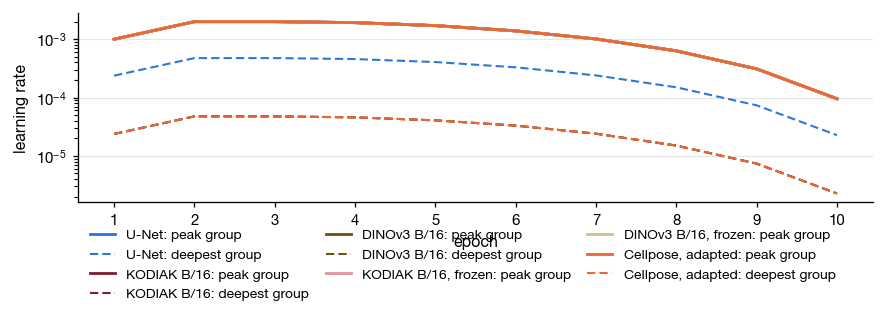

In [6]:
fig, ax = plt.subplots(figsize=(7.6, 2.5))
handles, lo_all, hi_all = [], [], []
for row in rows:
    g = row.runs[0].lr_groups()                                       # the schedule is the same for every seed
    if not len(g):
        continue
    hi, lo = g.max(axis=1), g.min(axis=1)
    ax.plot(hi.index + 1, hi.values, "-", lw=1.5, color=row.color)
    handles.append(plt.Line2D([], [], color=row.color, lw=1.5, label=f"{row.label}: peak group"))
    if not np.allclose(hi.values, lo.values):
        ax.plot(lo.index + 1, lo.values, ls=(0, (4, 2)), lw=1.1, color=row.color)
        handles.append(plt.Line2D([], [], color=row.color, lw=1.1, ls=(0, (4, 2)), label=f"{row.label}: deepest group"))
    lo_all.append(lo.min()); hi_all.append(hi.max())
if hi_all and max(hi_all) / max(min(lo_all), 1e-12) > 10:
    ax.set_yscale("log")
else:
    ax.yaxis.set_major_formatter(ScalarFormatter(useMathText=True)); ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
ax.set(xlabel="epoch", ylabel="learning rate")
ygrid(ax); epoch_axis(ax)
fig.subplots_adjust(bottom=0.32)
finish(fig, "ft_lr", handles, ncol=3)

**Figure 5 — The learning-rate schedule, as applied** (one seed per row: the schedule does not depend on the seed). The
optimizer group at the peak rate (the new decoder or head, solid) and the deepest trained group (dashed; absent when the
encoder is frozen or trains at one rate). The shared recipe of every row: two warm-up epochs, cosine decay to 1 % of the
peak, and layer-wise decay of 0.75 per layer down a pretrained encoder — so the solid curves coincide and the dashed ones
sit lower by the encoder's depth.

## 6. The kept weights, and how fast each run got there

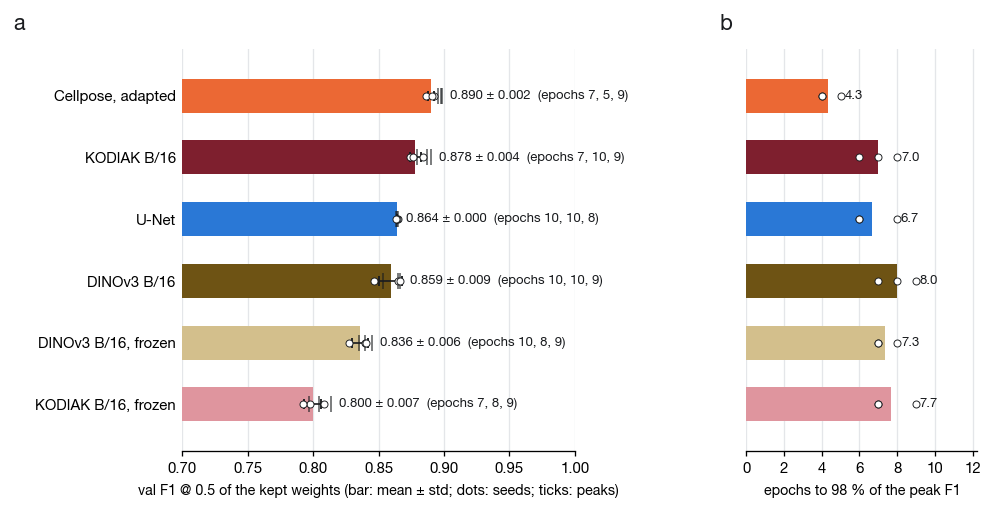

           row               label  seed  kept_f1  kept_epoch  peak_f1  within_2pct  done
    unet_flows               U-Net     0    0.865          10    0.865            6  True
    unet_flows               U-Net     1    0.864          10    0.864            8  True
    unet_flows               U-Net     2    0.864           8    0.864            6  True
 kodiakb_flows         KODIAK B/16     0    0.874           7    0.890            6  True
 kodiakb_flows         KODIAK B/16     1    0.877          10    0.879            8  True
 kodiakb_flows         KODIAK B/16     2    0.884           9    0.887            7  True
 dinov3b_flows         DINOv3 B/16     0    0.865          10    0.865            7  True
 dinov3b_flows         DINOv3 B/16     1    0.847          10    0.853            9  True
 dinov3b_flows         DINOv3 B/16     2    0.866           9    0.866            8  True
kodiakb_frozen KODIAK B/16, frozen     0    0.798           7    0.805            7  True
kodiakb_fr

In [7]:
recs = []
for row in rows:
    for r in row.runs:
        vm = r.val
        if not len(vm) or "val/f1" not in vm:
            continue
        k = r.kept(vm)
        peak = float(vm["val/f1"].max())
        best = float(k["val/f1"]) if k is not None else peak
        epoch = int(k["epoch"]) if k is not None else int(vm.loc[vm["val/f1"].idxmax(), "epoch"])
        recs.append({"row": row.name, "label": row.label, "seed": r.seed, "kept_f1": best, "kept_epoch": epoch + 1, "peak_f1": peak,
                     "within_2pct": int(vm.loc[vm["val/f1"] >= 0.98 * peak, "epoch"].iloc[0]) + 1, "done": r.done, "color": row.color})
per_seed = pd.DataFrame(recs)
if len(per_seed):
    summary = per_seed.groupby(["row", "label", "color"], sort=False).agg(kept_f1=("kept_f1", "mean"), kept_sd=("kept_f1", lambda s: s.std(ddof=0)),
                                                                          peak_f1=("peak_f1", "mean"), within=("within_2pct", "mean"),
                                                                          seeds=("seed", "count"), done=("done", "all")).reset_index().sort_values("kept_f1", ascending=False)
    n = len(summary)
    y = np.arange(n)[::-1]
    fig = plt.figure(figsize=(7.6, 0.36 * n + 1.7))
    gs = fig.add_gridspec(1, 2, width_ratios=[1.7, 1], wspace=0.55)
    a1 = fig.add_subplot(gs[0])
    a1.barh(y, summary.kept_f1, xerr=summary.kept_sd.fillna(0), color=list(summary.color), height=0.55, zorder=3, error_kw=dict(lw=0.9, capsize=2.5, ecolor=INK))
    for yi, s in zip(y, summary.itertuples()):
        pts = per_seed[per_seed.row == s.row]
        a1.scatter(pts.kept_f1, np.full(len(pts), yi), s=14, color="white", edgecolor=INK, lw=0.5, zorder=5)
        a1.scatter(pts.peak_f1, np.full(len(pts), yi), marker="|", s=70, color=INK, zorder=4, lw=1.0, alpha=0.6)
        ep = ", ".join(str(e) for e in pts.sort_values("seed").kept_epoch)
        a1.text(max(s.kept_f1 + (s.kept_sd or 0), pts.peak_f1.max()) + 0.006, yi,
                (f"{s.kept_f1:.3f} ± {s.kept_sd:.3f}" if s.seeds > 1 else f"{s.kept_f1:.3f}") + f"  (epoch{'s' if s.seeds > 1 else ''} {ep}{'' if s.done else '; still training'})", va="center", fontsize=7, color=INK)
    a1.set_ylim(-0.75, n - 0.25)
    a1.set_yticks(y, list(summary.label))
    lo = np.floor((per_seed.kept_f1.min() - 0.08) * 10) / 10
    a1.set_xlim(max(0, lo), min(1.0, per_seed.peak_f1.max() + 0.22))
    a1.set_xlabel("val F1 @ 0.5 of the kept weights (bar: mean ± std; dots: seeds; ticks: peaks)", fontsize=7.6)
    xgrid(a1); a1.spines["left"].set_visible(False); a1.tick_params(axis="y", length=0)
    panel(a1, "a", dx=-0.4)
    a2 = fig.add_subplot(gs[1])
    a2.barh(y, summary.within, color=list(summary.color), height=0.55, zorder=3)
    for yi, s in zip(y, summary.itertuples()):
        pts = per_seed[per_seed.row == s.row]
        a2.scatter(pts.within_2pct, np.full(len(pts), yi), s=14, color="white", edgecolor=INK, lw=0.5, zorder=5)
        a2.text(max(s.within, pts.within_2pct.max()) + 0.2, yi, f"{s.within:.1f}", va="center", fontsize=7, color=INK)
    a2.set_ylim(-0.75, n - 0.25)
    a2.set_yticks([]); a2.set_xlim(0, per_seed.within_2pct.max() * 1.25 + 1)
    a2.set_xlabel("epochs to 98 % of the peak F1", fontsize=7.6); a2.xaxis.set_major_locator(MaxNLocator(integer=True))
    xgrid(a2); a2.spines["left"].set_visible(False)
    panel(a2, "b", dx=-0.06)
    finish(fig, "ft_kept")
    print(per_seed.drop(columns="color").round(3).to_string(index=False))
else:
    print("no validation metrics yet")

**Figure 6 — What each method keeps, and how fast it got there.** (a) Validation F1 of the kept weights (each seed's
minimum validation-loss epoch, listed), mean ± std over seeds with the seeds as circles and each seed's peak F1 as a
tick — the distance from circle to tick is what the loss-based selection costs, or gains, over picking the best-looking
epoch. (b) The first epoch at which a seed came within 2 % of its own peak F1, mean over seeds: the convergence-speed
reading, where a slide-pretrained encoder is expected to arrive earlier than a frozen probe or the foundation it
started from. Test-slide numbers come from `mxseg eval … --unit region` on SLIDE-0236 (notebooks 02 and 07), never from these
validation curves.